# Cel analizy i pytania badawcze

Celem analizy jest zbadanie zależności pomiędzy wybranymi wskaźnikami
działalności przedsiębiorstwa Meta Platforms oraz ocenienie możliwości
wykorzystania modeli regresji do przewidywania ich wartości.

Sformułowano następujące pytania badawcze:

1. Czy liczba aktywnych użytkowników Facebooka wykazuje trend liniowy,
   czy lepiej opisuje ją model kwadratowy?

2. Czy istnieje zależność pomiędzy przychodami przedsiębiorstwa Meta
   a liczbą zatrudnionych pracowników? Jaki charakter ma ta zależność?

3. Czy modele zbudowane na danych z lat 2007–2017 zachowują zdolność
   predykcyjną w kolejnych latach?

Analizę przeprowadzono z wykorzystaniem metody najmniejszych kwadratów
(MNK). Jakość modeli oceniono na podstawie współczynnika determinacji,
istotności parametrów oraz błędów predykcji.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.formula.api as smf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"

WORKBOOK = DATA_DIR / "MED-Lab-1-Zadanie-1-Dane.xlsx"

assert WORKBOOK.exists(), f"File not found: {WORKBOOK}"

print("Workbook:", WORKBOOK)

Workbook: /home/patryk_pc/Projects/MED/MED-Lab-project/data/raw/MED-Lab-1-Zadanie-1-Dane.xlsx


In [2]:
annual = pd.read_excel(
    WORKBOOK,
    sheet_name="Użytk-Przych-Zysk-Zatr",
)

annual = annual.rename(columns={
    "Rok": "year",
    "Przychod": "revenue",
    "Zysk": "profit",
    "Zatrudnienie": "employees",
    "Uzytk": "users",
})

annual = annual.dropna(subset=["year"]).copy()

print("Shape:", annual.shape)
print("Missing values:")
display(annual.isna().sum())

display(annual)

Shape: (21, 5)
Missing values:


year         0
revenue      2
profit       2
employees    2
users        6
dtype: int64

,year,revenue,profit,employees,users
0,2007,153,-138.0,450.0,NaN
1,2008,272,-56.0,850.0,NaN
2,2009,777,229.0,1218.0,360.0
3,2010,1974,606.0,2127.0,608.0
4,2011,3711,1000.0,3200.0,845.0
5,2012,5089,53.0,4619.0,1056.0
6,2013,7872,1500.0,6337.0,1228.0
7,2014,12466,2940.0,9199.0,1393.0
8,2015,17928,3688.0,12691.0,1591.0
9,2016,27638,10217.0,17048.0,1860.0


In [3]:
# Convert columns to numeric values.
numeric_columns = ["year", "revenue", "profit", "employees", "users"]

for column in numeric_columns:
    annual[column] = pd.to_numeric(
        annual[column],
        errors="coerce"
    )

# Remove rows without a valid year.
annual = annual.dropna(subset=["year"]).copy()

# Remove rows where all measured variables are missing.
measurement_columns = ["revenue", "profit", "employees", "users"]

annual = annual.dropna(
    subset=measurement_columns,
    how="all"
).copy()

# Convert year to integer.
annual["year"] = annual["year"].astype(int)

# Sort observations chronologically.
annual = annual.sort_values("year").reset_index(drop=True)

print("Shape:", annual.shape)
print("\nMissing values:")
display(annual.isna().sum())

display(annual)

Shape: (19, 5)

Missing values:


year         0
revenue      0
profit       0
employees    0
users        4
dtype: int64

,year,revenue,profit,employees,users
0,2007,153.0,-138.0,450.0,NaN
1,2008,272.0,-56.0,850.0,NaN
2,2009,777.0,229.0,1218.0,360.0
3,2010,1974.0,606.0,2127.0,608.0
4,2011,3711.0,1000.0,3200.0,845.0
5,2012,5089.0,53.0,4619.0,1056.0
6,2013,7872.0,1500.0,6337.0,1228.0
7,2014,12466.0,2940.0,9199.0,1393.0
8,2015,17928.0,3688.0,12691.0,1591.0
9,2016,27638.0,10217.0,17048.0,1860.0


In [4]:
quarterly = pd.read_excel(
    WORKBOOK,
    sheet_name="Uzytkownicy Q3'2008 -> Q4'2023",
    header=1,
)

quarterly = quarterly.dropna(subset=["Users"]).copy()

quarterly = quarterly[["NoQ", "QY", "Users"]]

quarterly = quarterly.rename(columns={
    "QY": "quarter",
    "Users": "users_millions",
})

parts = quarterly["quarter"].str.extract(
    r"Q([1-4])\s*'(\d{2})"
)

quarterly["quarter_num"] = parts[0].astype(int)
quarterly["year"] = 2000 + parts[1].astype(int)

# Q3 2008 = time 0
quarterly["time"] = (
    (quarterly["year"] - 2008) * 4
    + quarterly["quarter_num"] - 3
)

display(quarterly.head())
display(quarterly.tail())

,NoQ,quarter,users_millions,quarter_num,year,time
0,1,Q3 '08,100.0,3,2008,0
1,2,Q1 '09,197.0,1,2009,2
2,3,Q2 '09,242.0,2,2009,3
3,4,Q3 '09,305.0,3,2009,4
4,5,Q4 '09,360.0,4,2009,5


,NoQ,quarter,users_millions,quarter_num,year,time
56,57,Q4 '22,2963.0,4,2022,57
57,58,Q1 '23,2989.0,1,2023,58
58,59,Q2 '23,3030.0,2,2023,59
59,60,Q3 '23,3049.0,3,2023,60
60,61,Q4'23,3065.0,4,2023,61


In [5]:
annual_train = annual[
    annual["year"] <= 2017
].copy()

annual_test = annual[
    annual["year"] >= 2018
].copy()

users_train = quarterly[
    quarterly["year"] <= 2017
].copy()

users_test = quarterly[
    quarterly["year"] >= 2018
].copy()

print("Annual training:", annual_train.shape)
print("Annual testing:", annual_test.shape)

print("Users training:", users_train.shape)
print("Users testing:", users_test.shape)

Annual training: (11, 5)
Annual testing: (8, 5)
Users training: (37, 6)
Users testing: (24, 6)


# Eksploracyjna analiza danych

In [6]:
annual_corr = annual_train[
    ["year", "revenue", "profit", "employees"]
].corr()

display(annual_corr.round(3))

,year,revenue,profit,employees
year,1.000,0.893,0.800,0.917
revenue,0.893,1.000,0.978,0.998
profit,0.800,0.978,1.000,0.962
employees,0.917,0.998,0.962,1.000


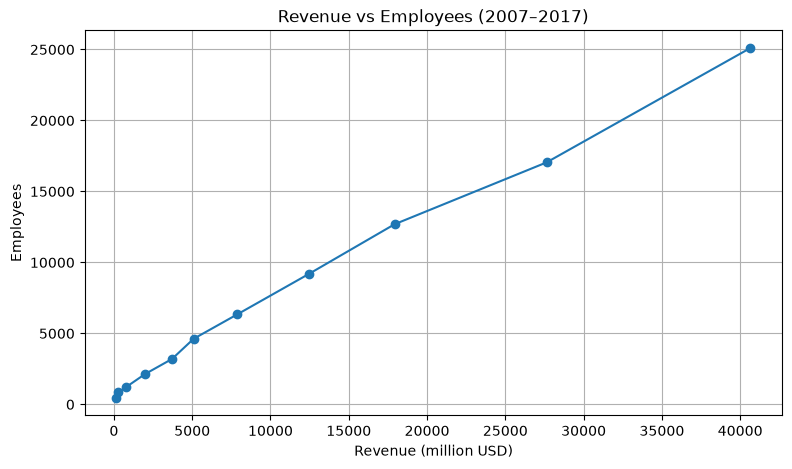

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(
    annual_train["revenue"],
    annual_train["employees"],
    marker="o",
)

plt.xlabel("Revenue (million USD)")
plt.ylabel("Employees")
plt.title("Revenue vs Employees (2007–2017)")
plt.grid()
plt.show()

# Wstępne obserwacje

Na podstawie wykresu zależności przychodów i zatrudnienia można
zauważyć silną dodatnią zależność pomiędzy analizowanymi zmiennymi.

Wzrostowi przychodów towarzyszy wzrost zatrudnienia. Na podstawie
samego wykresu nie można jednak jednoznacznie rozstrzygnąć,
czy zależność ma charakter liniowy, czy kwadratowy.

W celu dokładniejszego określenia charakteru zależności zostaną
oszacowane i porównane oba modele regresji.

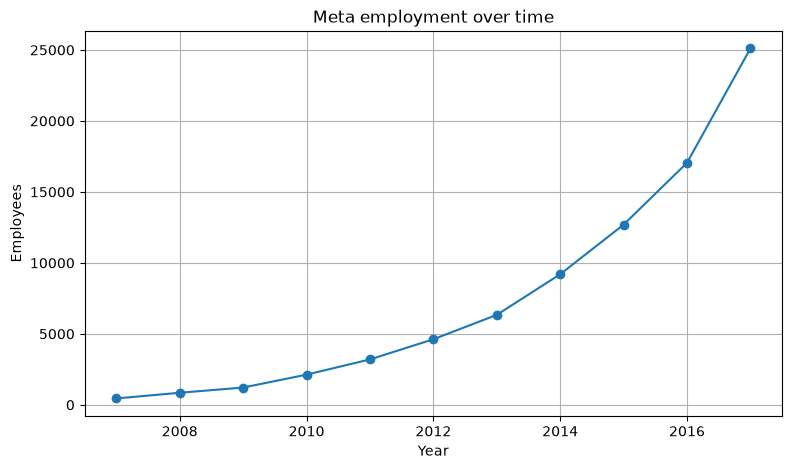

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(
    annual_train["year"],
    annual_train["employees"],
    marker="o",
)

plt.xlabel("Year")
plt.ylabel("Employees")
plt.title("Meta employment over time")
plt.grid()
plt.show()

Wykres przedstawia zmianę liczby zatrudnionych pracowników
przedsiębiorstwa Meta w latach 2007–2017.

Widoczny jest ogólny trend wzrostowy zatrudnienia.
Obserwacja ta stanowi dodatkowe uzasadnienie
do zbadania zależności pomiędzy przychodami
a liczbą pracowników.

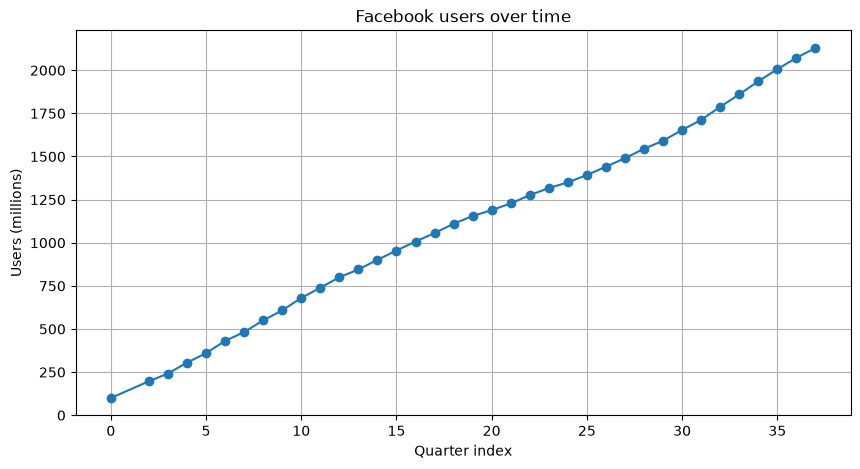

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(
    users_train["time"],
    users_train["users_millions"],
    marker="o",
)

plt.xlabel("Quarter index")
plt.ylabel("Users (millions)")
plt.title("Facebook users over time")
plt.grid()
plt.show()

Wykres przedstawia kwartalną liczbę aktywnych użytkowników
Facebooka w okresie od III kwartału 2008 do IV kwartału 2017.

Widoczny jest długoterminowy trend wzrostowy.
W celu określenia charakteru tej zależności zostaną
porównane modele regresji liniowej i kwadratowej.

# Budowa modeli regresji

## 1. Zależność zatrudnienia od przychodów

W pierwszej kolejności oszacowany zostanie model liniowy
opisujący zależność liczby zatrudnionych pracowników
od przychodów przedsiębiorstwa Meta.

In [10]:
annual_train["revenue_b"] = (
    annual_train["revenue"] / 1000
)

annual_test["revenue_b"] = (
    annual_test["revenue"] / 1000
)

linear_model = smf.ols(
    "employees ~ revenue_b",
    data=annual_train,
).fit()

print(linear_model.summary())

                            OLS Regression Results                            
Dep. Variable:              employees   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                     1866.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           9.53e-12
Time:                        15:47:06   Log-Likelihood:                -84.414
No. Observations:                  11   AIC:                             172.8
Df Residuals:                       9   BIC:                             173.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1074.6305    229.039      4.692      0.0

### Wyniki modelu liniowego

Oszacowane równanie regresji:

$$
\hat{Y}=1074{,}63+599{,}18X
$$

gdzie:
- $Y$ – liczba zatrudnionych pracowników,
- $X$ – przychody wyrażone w miliardach USD.

Współczynnik determinacji wynosi około $R^2=0{,}995$,
co oznacza bardzo dobre dopasowanie modelu do danych treningowych.

Wzrost przychodów o 1 miliard USD wiąże się w modelu ze wzrostem
przewidywanego zatrudnienia o około 599 osób.

Testujemy dla współczynników hipotezy $H_0: \alpha_j=0$
wobec $H_1: \alpha_j\ne0$ przy poziomie istotności $\alpha=0{,}05$.
Współczynnik przy przychodach jest istotny ($SE=13{,}870$,
$p<0{,}001$), dlatego odrzucamy $H_0$. Wyraz wolny również
jest istotny ($SE=229{,}039$, $p=0{,}001$).

In [11]:
revenue_mean = annual_train["revenue_b"].mean()

annual_train["revenue_c"] = (
    annual_train["revenue_b"] - revenue_mean
)

annual_test["revenue_c"] = (
    annual_test["revenue_b"] - revenue_mean
)

quadratic_model = smf.ols(
    "employees ~ revenue_c + I(revenue_c ** 2)",
    data=annual_train,
).fit()

print(quadratic_model.summary())

                            OLS Regression Results                            
Dep. Variable:              employees   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                     1582.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           4.05e-11
Time:                        15:47:06   Log-Likelihood:                -80.877
No. Observations:                  11   AIC:                             167.8
Df Residuals:                       8   BIC:                             168.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          7924.3280    198.01

### Wyniki modelu kwadratowego

Oszacowany model:

$$
\hat{Y}=7924{,}328+638{,}881X_c-2{,}5104X_c^2
$$

gdzie:

$$
X_c=X-\bar X
$$

Testujemy dla współczynników hipotezy $H_0: \alpha_j=0$
wobec $H_1: \alpha_j\ne0$ przy poziomie istotności $\alpha=0{,}05$.
Współczynnik przy $X_c$ jest istotny ($SE=18{,}221$,
$p<0{,}001$). Współczynnik przy $X_c^2$ również jest istotny
($SE=0{,}934$, $p=0{,}028$). Dla obu składników odrzucamy
$H_0$. Istotny jest także wyraz wolny ($SE=198{,}012$,
$p<0{,}001$).

Model kwadratowy uzyskał wyższy współczynnik determinacji
niż model liniowy. Nie oznacza to jednak automatycznie,
że będzie lepiej przewidywał wartości w kolejnych latach.

In [12]:
# Miary jakości dopasowania modeli

def model_quality(model, name):

    se = np.sqrt(model.mse_resid)

    y_mean = model.model.endog.mean()

    we = (se / y_mean) * 100

    return {
        "Model": name,
        "R2": model.rsquared,
        "Adjusted R2": model.rsquared_adj,
        "Se": se,
        "We (%)": we,
    }


employment_quality = pd.DataFrame([
    model_quality(linear_model, "Linear"),
    model_quality(quadratic_model, "Quadratic"),
])

display(employment_quality.round(4))

,Model,R2,Adjusted R2,Se,We (%)
0,Linear,0.9952,0.9947,575.6124,7.6430
1,Quadratic,0.9975,0.9968,442.6325,5.8773


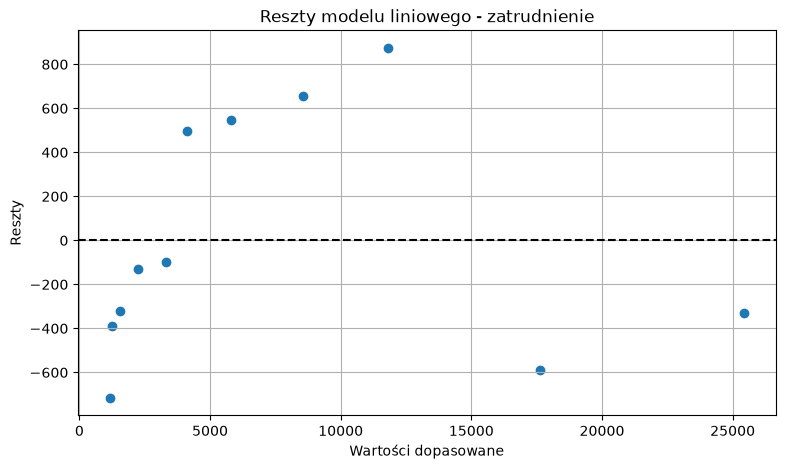

In [13]:
# Analiza reszt modelu liniowego

plt.figure(figsize=(9, 5))

plt.scatter(
    linear_model.fittedvalues,
    linear_model.resid,
)

plt.axhline(0, linestyle="--", color="black")

plt.xlabel("Wartości dopasowane")
plt.ylabel("Reszty")
plt.title("Reszty modelu liniowego - zatrudnienie")

plt.grid()
plt.show()

Wykres reszt pozwala ocenić, czy błędy modelu mają
przypadkowy charakter.

Szczególną uwagę należy zwrócić na występowanie
systematycznych wzorców oraz zmianę rozrzutu reszt
wraz ze wzrostem wartości dopasowanych.

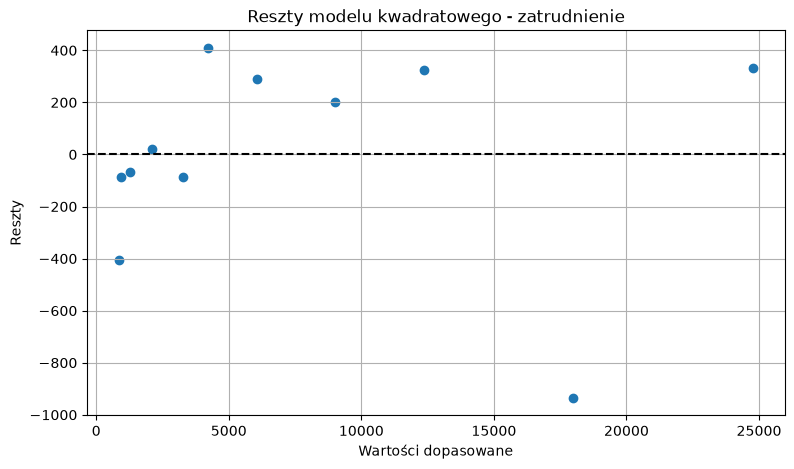

In [14]:
# Analiza reszt modelu kwadratowego

plt.figure(figsize=(9, 5))

plt.scatter(
    quadratic_model.fittedvalues,
    quadratic_model.resid,
)

plt.axhline(0, linestyle="--", color="black")

plt.xlabel("Wartości dopasowane")
plt.ylabel("Reszty")
plt.title("Reszty modelu kwadratowego - zatrudnienie")

plt.grid()
plt.show()

### Interpretacja wykresu reszt modelu kwadratowego

Reszty modelu kwadratowego są rozmieszczone po obu stronach
linii zerowej, jednak nie tworzą całkowicie losowego układu.
Widoczne są znaczne odchylenia wartości rzeczywistych od
wartości przewidywanych, szczególnie dla większych wartości
dopasowanych.

Największa ujemna reszta wynosi około -940, co oznacza
znaczne przeszacowanie zatrudnienia przez model dla tej
obserwacji. Występują również obserwacje z dodatnimi resztami
przekraczającymi 300.

Wyniki wskazują, że pomimo wysokiego współczynnika
determinacji model kwadratowy nie opisuje idealnie zależności
między przychodami a zatrudnieniem. Sam wysoki poziom R²
nie gwarantuje bowiem poprawności modelu.

# Predykcja i sprawdzanie jakości modeli

In [15]:
def forecast_metrics(actual, predicted):

    error = actual - predicted

    return {
        "ME": error.mean(),
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE": (
            np.mean(
                np.abs(error / actual)
            ) * 100
        ),
    }
annual_test["pred_linear"] = (
    linear_model.predict(annual_test)
)

annual_test["pred_quadratic"] = (
    quadratic_model.predict(annual_test)
)

display(
    annual_test[
        [
            "year",
            "employees",
            "pred_linear",
            "pred_quadratic",
        ]
    ].round(2)
)

,year,employees,pred_linear,pred_quadratic
11,2018,35587.0,34531.86,31616.18
12,2019,44942.0,43435.13,37193.26
13,2020,58604.0,52583.47,41769.13
14,2021,71970.0,71735.79,47558.87
15,2022,86482.0,70944.87,47421.32
16,2023,67317.0,81423.99,48533.88
17,2024,74067.0,99640.98,46812.72
18,2025,78865.0,121490.22,38627.22


In [16]:
periods = {
    "2018-2020": (2018, 2020),
    "2021-2023": (2021, 2023),
    "2024-2025": (2024, 2025),
}

for name, (start, end) in periods.items():

    part = annual_test[
        annual_test["year"].between(start, end)
    ]

    print(f"\n{name}")

    print(
        "Linear:",
        forecast_metrics(
            part["employees"],
            part["pred_linear"],
        ),
    )

    print(
        "Quadratic:",
        forecast_metrics(
            part["employees"],
            part["pred_quadratic"],
        ),
    )


2018-2020
Linear: {'ME': np.float64(2860.8435250544717), 'MAE': np.float64(2860.8435250544717), 'RMSE': np.float64(3634.588200425109), 'MAPE': np.float64(5.530367349396658)}
Quadratic: {'ME': np.float64(9518.143951493435), 'MAE': np.float64(9518.143951493435), 'RMSE': np.float64(10942.627936605957), 'MAPE': np.float64(19.042065380511534)}

2021-2023
Linear: {'ME': np.float64(554.7845699941341), 'MAE': np.float64(9959.446320813155), 'RMSE': np.float64(12116.994206896834), 'MAPE': np.float64(13.08241203039736)}
Quadratic: {'ME': np.float64(27418.3093134246), 'MAE': np.float64(27418.3093134246), 'RMSE': np.float64(28719.595817024634), 'MAPE': np.float64(35.662407322592976)}

2024-2025
Linear: {'ME': np.float64(-34099.60102484583), 'MAE': np.float64(34099.60102484583), 'RMSE': np.float64(35149.23887000429), 'MAPE': np.float64(44.28825442740204)}
Quadratic: {'ME': np.float64(33746.033005183854), 'MAE': np.float64(33746.033005183854), 'RMSE': np.float64(34364.771876669445), 'MAPE': np.float

### Wnioski z predykcji zatrudnienia

Porównanie błędów predykcji wykazało, że model liniowy osiągał mniejsze błędy niż model kwadratowy w okresach 2018–2020 oraz 2021–2023.

W okresie 2018–2020 wartość MAPE wyniosła 5,53% dla modelu liniowego oraz 19,04% dla modelu kwadratowego. W latach 2021–2023 wartości te wyniosły odpowiednio 13,08% i 35,66%.

W okresie 2024–2025 oba modele osiągnęły zbliżone, lecz znacznie wyższe błędy predykcji: MAPE wyniósł 44,29% dla modelu liniowego oraz 43,91% dla kwadratowego.

Wyniki wskazują, że lepsze dopasowanie modelu kwadratowego do danych treningowych nie przełożyło się na lepszą zdolność predykcyjną w kolejnych latach.

# 2. Analiza kwartalnej liczby użytkowników Facebooka

W drugim etapie zbadano zależność pomiędzy czasem
a liczbą aktywnych użytkowników Facebooka.

Porównane zostaną modele liniowy i kwadratowy.
Następnie zostanie oceniona ich zdolność predykcyjna
na podstawie danych kwartalnych z lat 2018–2023.

In [17]:
users_linear = smf.ols(
    "users_millions ~ time",
    data=users_train,
).fit()

print(users_linear.summary())

                            OLS Regression Results                            
Dep. Variable:         users_millions   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                     8516.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           2.18e-43
Time:                        15:47:07   Log-Likelihood:                -185.28
No. Observations:                  37   AIC:                             374.6
Df Residuals:                      35   BIC:                             377.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    122.9207     12.432      9.888      0.0

In [18]:
time_mean = users_train["time"].mean()

users_train["time_c"] = (
    users_train["time"] - time_mean
)

users_test["time_c"] = (
    users_test["time"] - time_mean
)

users_quadratic = smf.ols(
    "users_millions ~ time_c + I(time_c ** 2)",
    data=users_train,
).fit()

print(users_quadratic.summary())

                            OLS Regression Results                            
Dep. Variable:         users_millions   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                     4171.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           2.21e-41
Time:                        15:47:07   Log-Likelihood:                -185.13
No. Observations:                  37   AIC:                             376.3
Df Residuals:                      34   BIC:                             381.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept       1125.2469      9.213    122.

### Istotność parametrów modeli kwartalnych

Testujemy dla każdego współczynnika $H_0: \alpha_j=0$
wobec $H_1: \alpha_j\ne0$ przy poziomie istotności $\alpha=0{,}05$.
W modelu liniowym współczynnik przy czasie jest istotny
($SE=0{,}570$, $p<0{,}001$). W modelu kwadratowym współczynnik
przy $time_c$ jest istotny ($SE=0{,}576$, $p<0{,}001$), natomiast
współczynnik przy $time_c^2$ nie jest istotny
($SE=0{,}059$, $p=0{,}599$); nie ma podstaw do odrzucenia
$H_0$ dla składnika kwadratowego. Wyrazy wolne obu modeli
również są istotne ($p<0{,}001$). Powyższe testy należy
interpretować ostrożnie z powodu autokorelacji reszt opisanej
poniżej.

In [19]:
# Porównanie jakości modeli użytkowników

users_quality = pd.DataFrame([
    model_quality(users_linear, "Linear"),
    model_quality(users_quadratic, "Quadratic"),
])

display(users_quality.round(4))

,Model,R2,Adjusted R2,Se,We (%)
0,Linear,0.9959,0.9958,37.2085,3.3174
1,Quadratic,0.9959,0.9957,37.5964,3.3520


### Ograniczenia modeli kwartalnych

W wynikach estymacji obu modeli kwartalnych uzyskano
bardzo niskie wartości statystyki Durbin-Watsona
(około 0,10).

Wskazuje to na silną dodatnią autokorelację reszt.
Oznacza to, że założenie niezależności składników
losowych może nie być spełnione.

W związku z tym wyniki testów istotności parametrów
należy interpretować z ostrożnością.

In [20]:
# Predykcja kwartalnej liczby użytkowników

users_test["pred_linear"] = users_linear.predict(
    users_test
)

users_test["pred_quadratic"] = users_quadratic.predict(
    users_test
)

display(
    users_test[
        [
            "quarter",
            "year",
            "users_millions",
            "pred_linear",
            "pred_quadratic",
        ]
    ].round(2)
)

,quarter,year,users_millions,pred_linear,pred_quadratic
37,Q1 '18,2018,2196.0,2123.17,2115.28
38,Q2 '18,2018,2234.0,2175.81,2166.69
39,Q3 '18,2018,2271.0,2228.44,2218.02
40,Q4 '18,2018,2320.0,2281.08,2269.30
41,Q1 '19,2019,2375.0,2333.72,2320.51
42,Q2 '19,2019,2414.0,2386.36,2371.66
43,Q3 '19,2019,2449.0,2439.00,2422.75
44,Q4 '19,2019,2498.0,2491.63,2473.77
45,Q1 '20,2020,2603.0,2544.27,2524.73
46,Q2 '20,2020,2701.0,2596.91,2575.63


In [21]:
# Ocena jakości predykcji użytkowników

user_periods = {
    "2018-2020": (2018, 2020),
    "2021-2023": (2021, 2023),
}

for name, (start, end) in user_periods.items():

    part = users_test[
        users_test["year"].between(start, end)
    ]

    print(f"\n{name}")

    print("Linear:")
    print(
        forecast_metrics(
            part["users_millions"],
            part["pred_linear"],
        )
    )

    print("Quadratic:")
    print(
        forecast_metrics(
            part["users_millions"],
            part["pred_quadratic"],
        )
    )


2018-2020
Linear:
{'ME': np.float64(53.82268760242323), 'MAE': np.float64(53.82268760242323), 'RMSE': np.float64(61.9676484655932), 'MAPE': np.float64(2.1516830337397526)}
Quadratic:
{'ME': np.float64(69.66140452339876), 'MAE': np.float64(69.66140452339876), 'RMSE': np.float64(77.20984443551792), 'MAPE': np.float64(2.7808495670532483)}

2021-2023
Linear:
{'ME': np.float64(-86.5009781876859), 'MAE': np.float64(125.76950976282171), 'RMSE': np.float64(149.07085838345813), 'MAPE': np.float64(4.2068146807717035)}
Quadratic:
{'ME': np.float64(-47.50515676288645), 'MAE': np.float64(107.58029780669237), 'RMSE': np.float64(123.04327784116482), 'MAPE': np.float64(3.6119077337871097)}


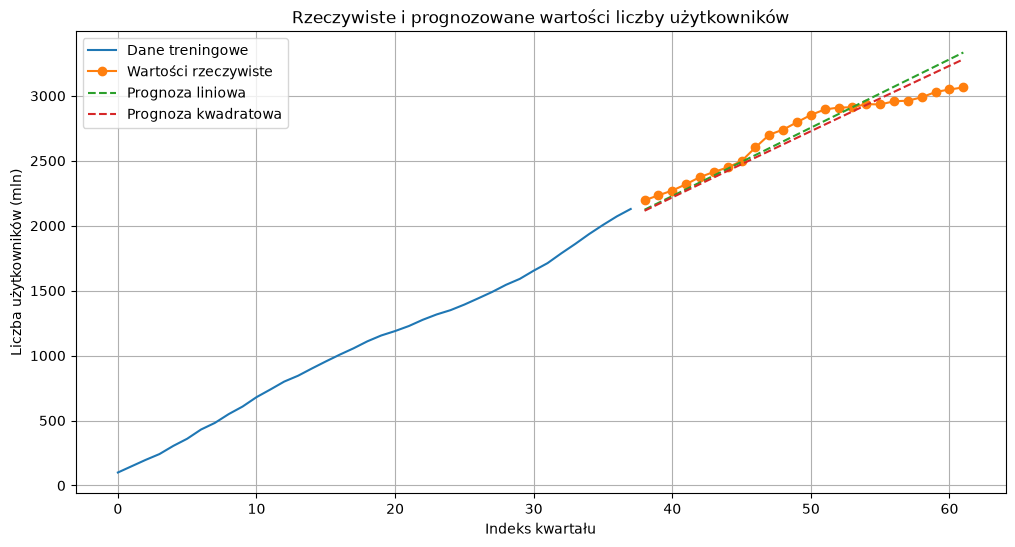

In [22]:
# Porównanie rzeczywistych i prognozowanych wartości

plt.figure(figsize=(12, 6))

plt.plot(
    users_train["time"],
    users_train["users_millions"],
    label="Dane treningowe",
)

plt.plot(
    users_test["time"],
    users_test["users_millions"],
    label="Wartości rzeczywiste",
    marker="o",
)

plt.plot(
    users_test["time"],
    users_test["pred_linear"],
    label="Prognoza liniowa",
    linestyle="--",
)

plt.plot(
    users_test["time"],
    users_test["pred_quadratic"],
    label="Prognoza kwadratowa",
    linestyle="--",
)

plt.xlabel("Indeks kwartału")
plt.ylabel("Liczba użytkowników (mln)")
plt.title("Rzeczywiste i prognozowane wartości liczby użytkowników")

plt.legend()
plt.grid()
plt.show()

### Wnioski z predykcji liczby użytkowników

Porównanie błędów predykcji wykazało, że model liniowy osiągnął lepsze wyniki w okresie 2018–2020. Wartość MAPE wyniosła wtedy 2,15% dla modelu liniowego oraz 2,78% dla modelu kwadratowego.

W okresie 2021–2023 model kwadratowy uzyskał mniejsze błędy predykcji. Wartość MAPE wyniosła 3,61%, podczas gdy dla modelu liniowego osiągnęła 4,21%.

Różnice pomiędzy modelami są stosunkowo niewielkie. Należy jednak pamiętać o silnej autokorelacji reszt, która ogranicza wiarygodność klasycznej inferencji statystycznej.

Dane kwartalne kończą się na IV kwartale 2023 roku, dlatego nie jest możliwa weryfikacja predykcji dla lat 2024–2025.

# Podsumowanie i wnioski końcowe

W ramach zadania przeprowadzono analizę zależności
pomiędzy wybranymi wskaźnikami działalności
przedsiębiorstwa Meta oraz liczbą aktywnych
użytkowników Facebooka.

W pierwszej części zbadano zależność pomiędzy
przychodami a zatrudnieniem. Porównano modele
regresji liniowej i kwadratowej.

Model kwadratowy uzyskał wyższy współczynnik
determinacji, a jego składnik kwadratowy okazał się
istotny statystycznie przy poziomie istotności 0,05.
Jednak predykcja ex post wykazała, że model liniowy
osiągał mniejsze błędy w okresach 2018–2020
oraz 2021–2023.

W drugiej części przeanalizowano kwartalną liczbę
użytkowników Facebooka. Składnik kwadratowy
nie okazał się istotny statystycznie
(p-value = 0,599).

Porównanie predykcji wykazało, że model liniowy
lepiej przewidywał wartości w okresie 2018–2020,
natomiast model kwadratowy uzyskał mniejsze błędy
w okresie 2021–2023.

Analiza wykazała również ograniczenia modeli,
w szczególności występowanie autokorelacji reszt
w kwartalnych szeregach danych.

Ostatecznie stwierdzono, że ocena jakości modelu
nie powinna opierać się wyłącznie na współczynniku
determinacji. Istotne znaczenie mają również
istotność parametrów, diagnostyka reszt oraz
zdolność predykcyjna na danych testowych.